# DJAI

**Stage 1: playlist → audio features → segments → transition candidates.** 

## 1 — Imports and local paths
Place WAV/MP3/FLAC files in `data/audio/` (not tracked by Git).

In [2]:
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import librosa

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
AUDIO_DIR = PROJECT_ROOT / "data" / "audio"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
AUDIO_EXTENSIONS = {".wav", ".mp3", ".flac", ".aiff", ".ogg"}
audio_paths = sorted(p for p in AUDIO_DIR.rglob("*") if p.suffix.lower() in AUDIO_EXTENSIONS)
print(f"Found {len(audio_paths)} audio files in {AUDIO_DIR}")
if not audio_paths:
    print("Add audio files to data/audio/ before running the remaining cells.")

Found 6 audio files in C:\Users\Owner\Downloads\DJAIvscode\data\audio


## 2 — Audio analysis and segment extraction
We use **non-overlapping 16-beat windows (4 bars in 4/4)** as an initial baseline. This is *not* reliable downbeat/phrase identification. Key is estimated at track level; energy is measured per segment. Beat times stored in `Segment` are **segment-relative**.

In [3]:
def estimate_key(y, sr):
    # Compute chromagram
    chroma = librosa.feature.chroma_cqt(y=y, sr=sr)
    chroma_vals = np.sum(chroma, axis=1)

    # Major and minor pitch profiles
    maj_profile = np.array([6.35, 2.23, 3.48, 2.33, 4.38, 4.09, 2.52, 5.19, 2.39, 3.66, 2.29, 2.88])
    min_profile = np.array([6.33, 2.68, 3.52, 5.38, 2.60, 3.53, 2.54, 4.75, 3.98, 2.69, 3.34, 3.17])

    keys = ['C', 'C#', 'D', 'D#', 'E', 'F', 'F#', 'G', 'G#', 'A', 'A#', 'B']

    maj_corrs = [np.corrcoef(chroma_vals, np.roll(maj_profile, i))[0, 1] for i in range(12)]
    min_corrs = [np.corrcoef(chroma_vals, np.roll(min_profile, i))[0, 1] for i in range(12)]

    if max(maj_corrs) > max(min_corrs):
        return f"{keys[np.argmax(maj_corrs)]} Major"
    else:
        return f"{keys[np.argmax(min_corrs)]} Minor"

In [4]:
@dataclass
class Segment:
    segment_id: str
    song_id: str
    audio_path: str
    start_time: float
    end_time: float
    bpm: float
    beat_times: np.ndarray  # seconds relative to segment start
    key: str
    mode: str
    energy: float
    phrase_length_bars: float
    exit_boundary_confidence: float = 0.5  # unverified boundaries
    entry_boundary_confidence: float = 0.5


def extract_segments(path, beats_per_segment=16):
    y, sr = librosa.load(path, sr=22050, mono=True)
    if y.size == 0:
        return []
    tempo, beat_frames = librosa.beat.beat_track(y=y, sr=sr)
    bpm = float(np.asarray(tempo).reshape(-1)[0])
    beat_times = librosa.frames_to_time(beat_frames, sr=sr)
    if bpm <= 0 or len(beat_times) < beats_per_segment + 1:
        return []
    key_label = estimate_key(y, sr)
    key, mode = key_label.split(" ", 1)
    result = []
    for first in range(0, len(beat_times) - beats_per_segment, beats_per_segment):
        start = float(beat_times[first]); end = float(beat_times[first + beats_per_segment])
        clip = y[int(start * sr):int(end * sr)]
        if clip.size == 0:
            continue
        relative_beats = beat_times[first:first + beats_per_segment + 1] - start
        result.append(Segment(
            segment_id=f"{path.stem}:{first}", song_id=path.stem,
            audio_path=str(path.resolve()), start_time=start, end_time=end,
            bpm=bpm, beat_times=relative_beats,
            key=key, mode=mode, energy=float(np.sqrt(np.mean(clip**2))),
            phrase_length_bars=beats_per_segment / 4,
        ))
    return result

segments = []
for path in audio_paths:
    try:
        found = extract_segments(path)
        segments.extend(found)
        print(f"{path.name}: {len(found)} segments")
    except Exception as exc:
        print(f"SKIPPED {path.name}: {exc}")
print(f"Total segments: {len(segments)}")

Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip).wav: 27 segments
Lady Gaga - Bad Romance (ILYAA Remix).wav: 28 segments
Nicky Minaj - Starships (ILYAA Remix).wav: 28 segments
Tove Lo - Talking Body (D VEL Remix).wav: 31 segments
Toxic - Britney Spears - Thom Cote Remix.wav: 20 segments
Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remix) [Extended Mix].wav: 15 segments
Total segments: 149


## 3 — Rule-based compatibility baseline
These functions are retained for comparison with a future learned scorer. Scores are **heuristics**, not validated judgments of musical quality.

In [5]:
# Initial sigma value (sensitivity parameter) = 0.10

def calculate_tempo_compatibility(bpm_a, bpm_b, sigma=0.10):

    if sigma <= 0: #make sure that we have initialized our sigma value!
        raise ValueError("Sigma must be positive.")

    #these are the k values from above, essentially it's our allowed speed ratios
    ratios = [0.5, 1.0, 2.0]

    #relative tempo differences
    differences = []

    for k in ratios:
        #and then we use the log to measure proportional differences (not absolute)
        difference = abs(np.log(bpm_a / (k * bpm_b)))
        differences.append((difference, k))

    #we want to minimize the difference (as we see in our function above)
    #we are essentially testing all speeds and selecting the most compatible one.
    relative_difference, best_k = min(differences, key=lambda x: x[0])

    #transform the distance into a score between 0 and 1
    compatibility = np.exp(
        -(relative_difference ** 2) / (2 * sigma ** 2)
    )

    return compatibility, best_k

In [6]:
##now we actually calculate this
##we USE A CIRCULAR MEAN because beat phases repeat every beat period (avoids issues when phase values wrap around the end of a beat interval)
def calculate_phase_offset(beats_a, beats_b, bpm):

    # Convert beat timestamps to arrays
    beats_a = np.asarray(beats_a)
    beats_b = np.asarray(beats_b)

    #beat period calculation
    beat_period = 60 / bpm

    #convert timestamps into circular phase angles
    phase_a = 2 * np.pi * beats_a / beat_period
    phase_b = 2 * np.pi * beats_b / beat_period

    #calculate average circular phase
    mean_a = np.angle(np.mean(np.exp(1j * phase_a)))
    mean_b = np.angle(np.mean(np.exp(1j * phase_b)))

    #calculate phase difference
    phase_difference = np.angle(np.exp(1j * (mean_b - mean_a)))

    #convert phase difference back into seconds
    time_offset = phase_difference * beat_period / (2 * np.pi)

    return time_offset

In [7]:
def calculate_alignment_quality(beats_a, beats_b, bpm, sigma=0.03):
  #sigma controls how sensitve the function is to timing inconsistencies.
  # 0.03 means we're using approximately 30 millisenconds as our timing-error scale
  #this parameter will eventually be tuned by our model...
    beats_a = np.asarray(beats_a, dtype=float)
    beats_b = np.asarray(beats_b, dtype=float)

    beat_period = 60 / bpm

    phase_a = 2 * np.pi * beats_a / beat_period
    phase_b = 2 * np.pi * beats_b / beat_period

    concentration_a = abs(np.mean(np.exp(1j * phase_a)))
    concentration_b = abs(np.mean(np.exp(1j * phase_b)))

    # Convert circular concentration into a timing-error estimate.
    # This is an approximate measure, not an exact RMS calculation.
    concentration = np.sqrt(
        concentration_a * concentration_b
    )

    timing_error = np.sqrt(
        max(0, -2 * np.log(max(concentration, 1e-12)))
    ) * beat_period / (2 * np.pi)

    alignment_score = np.exp(
        -(timing_error ** 2) / (2 * sigma ** 2)
    )

    return alignment_score

In [8]:
def calculate_rhythm_compatibility(
    bpm_a,
    bpm_b,
    beats_a,
    beats_b
): #we need beats and bpm for both input segments
#we can calculate the bpm difference without adjusting anything
    tempo_score, multiplier = calculate_tempo_compatibility(
        bpm_a,
        bpm_b
    )

    #adjust Segment B's beat timestamps to its matched playback speed.
    #we are essentially shifting the beats of B like we talked about earlier
    adjusted_beats_b = np.asarray(beats_b, dtype=float) / multiplier

    #the alignment score measures the consistency of the detected grids
    alignment_score = calculate_alignment_quality(
        beats_a,
        adjusted_beats_b, #we use the newly aligned beats of segment B here
        bpm_a
    )
    #the phase offset tells the arranger how to position B
    phase_offset = calculate_phase_offset(
        beats_a,
        adjusted_beats_b,
        bpm_a
    )

    rhythm_score = tempo_score * alignment_score #the overall rhythm score is our two calculated scores combined

    return {
        "rhythm_score": rhythm_score,
        "tempo_score": tempo_score,
        "alignment_score": alignment_score,
        "tempo_multiplier": multiplier,
        "phase_offset": phase_offset
    }

In [9]:
#create a dictionary assigning each pitch class a postion
circle_of_fifths = {
    "C": 0,
    "G": 1,
    "D": 2,
    "A": 3,
    "E": 4,
    "B": 5,
    "F#": 6,
    "C#": 7,
    "G#": 8,
    "D#": 9,
    "A#": 10,
    "F": 11
}

#there's also some names that represent the same pitch (I should've studied music theory)
enharmonic_equivalents = {
    "Db": "C#",
    "Eb": "D#",
    "Gb": "F#",
    "Ab": "G#",
    "Bb": "A#"
}
#there are also some major+minor relationships that share the same notes. IDK WHAT THIS MEANS FULLY THIS IS DEEP MUSIC THEORY
#to whoever is reading this, I wouldn't worry about it much, just know that these relationships help assign a higher compatibility score
pitch_classes = {
    "C": 0,
    "C#": 1,
    "D": 2,
    "D#": 3,
    "E": 4,
    "F": 5,
    "F#": 6,
    "G": 7,
    "G#": 8,
    "A": 9,
    "A#": 10,
    "B": 11
}

In [10]:
#the distance between two keys is the shortest number of steps between them on the circle
#since the circle is, well, a circle, we use d=min(|i-j|, 12-|i-j|)

def calculate_key_distance(key_a, key_b):

    key_a = enharmonic_equivalents.get(key_a, key_a)
    key_b = enharmonic_equivalents.get(key_b, key_b)

    if key_a not in circle_of_fifths:
        raise ValueError(f"Unknown key: {key_a}")

    if key_b not in circle_of_fifths:
        raise ValueError(f"Unknown key: {key_b}")

    position_a = circle_of_fifths[key_a]
    position_b = circle_of_fifths[key_b]

    distance = abs(position_a - position_b)

    return min(distance, 12 - distance)

In [11]:
def calculate_harmonic_compatibility(key_a, mode_a, key_b, mode_b):

#one thing that is important to note but not memorize is we use a custom score system
#THESE ARE JUST INITIAL WEIGHTS! We will tune them later within the model

# Same key = 1.00
# Relative major/minor = 0.95
# One step apart = 0.85
# Two steps apart = 0.65
# Three steps apart = 0.45
# Four or more steps apart = 0.25

#you'll see these scores below

    key_a = enharmonic_equivalents.get(key_a, key_a)
    key_b = enharmonic_equivalents.get(key_b, key_b)

    mode_a = mode_a.lower()
    mode_b = mode_b.lower()

    # Same tonic and mode
    if key_a == key_b and mode_a == mode_b:
        return 1.0 #aka same key

    # Check relative major/minor relationship
    semitone_difference = (
        pitch_classes[key_b] - pitch_classes[key_a]
    ) % 12

    if mode_a == "major" and mode_b == "minor":
        if semitone_difference == 9:
            return 0.95 #aka relative major/minor

    if mode_a == "minor" and mode_b == "major":
        if semitone_difference == 3:
            return 0.95 #aka relative major/minor

    # Same tonic, different mode
    if key_a == key_b:
        return 0.65 #aka two steps apart

    # Circle-of-fifths relationship
    distance = calculate_key_distance(key_a, key_b)

    scores = {
        1: 0.85, #if the relationship is one step apart on the circle
        2: 0.65, #if the relationship is two steps apart
        3: 0.45 #if three steps apart
    }

    if distance == 0:
        return 0.65

    return scores.get(distance, 0.25)

In [12]:
def calculate_energy_compatibility(
    energy_a,
    energy_b,
    target_delta=0.0,
    sigma=0.25
):

    energy_difference = energy_b - energy_a #this is the energy difference discussed above

    #and this is our Gaussian. Basically,
    #it is e to the power of the negative of actual energy difference minus target energy diference square
    #over 2 times the tolerance value squared
    compatibility = np.exp(
        -((energy_difference - target_delta) ** 2)
        / (2 * sigma ** 2)
    )

    return compatibility

In [13]:
def calculate_phrase_length_compatibility(
    phrase_a,
    phrase_b,
    sigma=0.15
):

    ratios = [0.5, 1.0, 2.0] #we allow 0.5, 1, and 2x phrase length relationships (similar to tempo system)
                              #so 4bars and 8bars is more compatible than we'd assume because we allow a 2x phrase length!

    differences = []

    for ratio in ratios:

        difference = abs(
            np.log(phrase_a / (ratio * phrase_b))
        )

        differences.append(difference)

    best_difference = min(differences) #we want to reward compatible phrase lengths as in 8bars and 8bars is excelletn
                                        #whereas 8bars and 7bars is less compatible

    compatibility = np.exp(
        -(best_difference ** 2) / (2 * sigma ** 2) #this is our gaussian function
    )

    return compatibility

In [14]:
def calculate_boundary_compatibility(
    exit_confidence, #how confident are we that segment a is approaching a suitable ending
    entry_confidence #how confident are we that segment b is approaching a suitable ending
):

    return np.sqrt(
        exit_confidence * entry_confidence #we use the mean because we want both boundaries to be strong!
    )

In [15]:
#we have both phrase length and boundary compatibility calculations... so we combine them
def calculate_phrase_compatibility(
    phrase_a,
    phrase_b,
    exit_confidence,
    entry_confidence
):

    length_score = calculate_phrase_length_compatibility(
        phrase_a,
        phrase_b
    )

    boundary_score = calculate_boundary_compatibility(
        exit_confidence,
        entry_confidence
    )

    phrase_score = length_score * boundary_score

    return {
        "phrase_score": phrase_score,
        "length_score": length_score,
        "boundary_score": boundary_score
    }

In [16]:
def evaluate_transition(segment_a, segment_b):
#our method will receieve two segments, calculate rhythm/harmonic/energy/phrase compatibility and combine the scores using our weights.
#then return the overall score and all component scores


    # -----------------------------
    # 1. RHYTHM COMPATIBILITY
    # -----------------------------

    rhythm_results = calculate_rhythm_compatibility(
        segment_a.bpm,
        segment_b.bpm,
        segment_a.beat_times,
        segment_b.beat_times
    )

    rhythm_score = rhythm_results["rhythm_score"]


    # -----------------------------
    # 2. HARMONIC COMPATIBILITY
    # -----------------------------

    harmonic_score = calculate_harmonic_compatibility(
        segment_a.key,
        segment_a.mode,
        segment_b.key,
        segment_b.mode
    )


    # -----------------------------
    # 3. ENERGY COMPATIBILITY
    # -----------------------------

    energy_score = calculate_energy_compatibility(
        segment_a.energy,
        segment_b.energy
    )


    # -----------------------------
    # 4. PHRASE COMPATIBILITY
    # -----------------------------

    phrase_results = calculate_phrase_compatibility(
        segment_a.phrase_length_bars,
        segment_b.phrase_length_bars,
        segment_a.exit_boundary_confidence,
        segment_b.entry_boundary_confidence
    )

    phrase_score = phrase_results["phrase_score"]


    # -----------------------------
    # 5. COMBINE SCORES
    # -----------------------------

    weights = {
        "rhythm": 0.35,
        "harmonic": 0.25,
        "energy": 0.20,
        "phrase": 0.20
    }

    transition_score = (
        rhythm_score * weights["rhythm"] +
        harmonic_score * weights["harmonic"] +
        energy_score * weights["energy"] +
        phrase_score * weights["phrase"]
    )


    # -----------------------------
    # 6. RETURN RESULTS
    # -----------------------------

    return {
        "transition_score": transition_score,

        "rhythm_score": rhythm_score,

        "harmonic_score": harmonic_score,

        "energy_score": energy_score,

        "phrase_score": phrase_score,

        "tempo_multiplier": rhythm_results["tempo_multiplier"],

        "phase_offset": rhythm_results["phase_offset"],

        "rhythm_details": rhythm_results,

        "phrase_details": phrase_results
    }

## 4 — Automatic candidate generation
Exclude self-transitions and same-song transitions for this initial demonstration. Limit candidates per segment to avoid quadratic memory growth for large playlists.

In [17]:
def generate_transition_candidates(segments, top_k=5):
    rows = []
    for a in segments:
        choices = []
        for b in segments:
            if a.song_id == b.song_id:
                continue
            scores = evaluate_transition(a, b)
            choices.append({
                "from_segment_id": a.segment_id,
                "to_segment_id": b.segment_id,
                "score": float(scores["transition_score"]),
                "tempo_multiplier": float(scores["tempo_multiplier"]),
                "phase_offset": float(scores["phase_offset"]),
            })
        rows.extend(sorted(choices, key=lambda r: r["score"], reverse=True)[:top_k])
    return pd.DataFrame(rows, columns=[
        "from_segment_id", "to_segment_id", "score", "tempo_multiplier", "phase_offset"
    ])

candidates_df = generate_transition_candidates(segments)
print(f"Candidate transitions: {len(candidates_df)}")
display(candidates_df.head(10))
if not candidates_df.empty:
    candidates_df.to_csv(OUTPUT_DIR / "transition_candidates.csv", index=False)

Candidate transitions: 745


,from_segment_id,to_segment_id,score,tempo_multiplier,phase_offset
0,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.839545,1.0,-7.989114e-05
1,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.836120,1.0,-5.497295e-03
2,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.834095,1.0,-1.349857e-15
3,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.828079,1.0,-2.060034e-02
4,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.827804,1.0,-1.229526e-02
5,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.848752,1.0,-2.748172e-03
6,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.845103,1.0,-8.165576e-03
7,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.843055,1.0,-2.668281e-03
8,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.836817,1.0,-2.326862e-02
9,Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH...,Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remi...,0.836543,1.0,-1.496354e-02


the cells above show us the specifics of the candidate generation. We can see what segment number is the outgoing, what segment number of the next song is incoming, their compatability score, whether the tempo was adjusted, and the phase offset (which is the beat alignment)

| Column | Meaning |
|---|---|
| `from_segment_id` | The segment DJAI would transition out of |
| `to_segment_id` | The segment DJAI would transition into |
| `score` | Estimated compatibility between the segments |
| `tempo_multiplier` | Suggested playback-speed adjustment |
| `phase_offset` | Estimated rhythmic alignment adjustment |

## 5 — Next implementation slots (do not paste code randomly)


1. **ArrangementPlan + TransitionInstruction:** insert after the candidate generation cell. Define the full ordered plan and transition parameters.
2. **Baseline planner:** select a coherent sequence from the candidate table, with reuse/energy constraints.
3. **VAE:** add feature matrix preparation, normalization, training, and embedding extraction in a separate section *after* the baseline is working.
4. **Learned transition scorer:** compare against `evaluate_transition` rather than deleting it.
5. **Audio renderer:** integrate the separate working engine after the planner is producing instructions.

**Known limitations:** No confirmed downbeats; fixed-length windows may cut phrases; track-level key estimates are approximate; raw RMS is not normalized across tracks; current transition scores are not trained; no audio is rendered here.

## Looking at an example transition

In [18]:
best = candidates_df.loc[candidates_df["score"].idxmax()]

print("BEST TRANSITION")
print("----------------------------")
print("From:", best["from_segment_id"])
print("To:", best["to_segment_id"])
print("Score:", best["score"])
print("Tempo multiplier:", best["tempo_multiplier"])
print("Phase offset:", best["phase_offset"])

BEST TRANSITION
----------------------------
From: Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip):288
To: Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remix) [Extended Mix]:48
Score: 0.8595870209668267
Tempo multiplier: 1.0
Phase offset: -0.0014206504859399559


## which variables are available to us?

In [19]:
print("Variables related to audio and segments:")
print("----------------------------------------")

for name, value in globals().copy().items():
    if any(word in name.lower() for word in [
        "audio", "track", "segment", "beat", "song"
    ]):
        if not name.startswith("_"):
            print(f"{name}: {type(value).__name__}")

Variables related to audio and segments:
----------------------------------------
AUDIO_DIR: WindowsPath
AUDIO_EXTENSIONS: set
audio_paths: list
Segment: type
extract_segments: function
segments: list


## Example of a returned segment (that would be used in a transition)

In [20]:
from dataclasses import fields, is_dataclass

print("SEGMENT CLASS")
print("----------------------------")

if is_dataclass(Segment):
    for field in fields(Segment):
        print(f"{field.name}: {field.type}")
else:
    print("Attributes:", vars(segments[0]))

print("\nFIRST SEGMENT")
print("----------------------------")
print(segments[0])

print("\nTOTAL SEGMENTS")
print("----------------------------")
print(len(segments))

SEGMENT CLASS
----------------------------
segment_id: <class 'str'>
song_id: <class 'str'>
audio_path: <class 'str'>
start_time: <class 'float'>
end_time: <class 'float'>
bpm: <class 'float'>
beat_times: <class 'numpy.ndarray'>
key: <class 'str'>
mode: <class 'str'>
energy: <class 'float'>
phrase_length_bars: <class 'float'>
exit_boundary_confidence: <class 'float'>
entry_boundary_confidence: <class 'float'>

FIRST SEGMENT
----------------------------
Segment(segment_id='Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip):0', song_id='Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip)', audio_path='C:\\Users\\Owner\\Downloads\\DJAIvscode\\data\\audio\\Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip).wav', start_time=0.9984580498866213, end_time=8.382403628117913, bpm=129.19921875, beat_times=array([0.        , 0.46439909, 0.92879819, 1.39319728, 1.85759637,
       2.32199546, 2.78639456, 3.2275737 , 3.69197279, 4.15637188,
       4.62077098, 5.08517007, 5.54956916, 6.01396825, 

## show us how we extract musical segments

In [21]:
import inspect

print(inspect.getsource(extract_segments))

def extract_segments(path, beats_per_segment=16):
    y, sr = librosa.load(path, sr=22050, mono=True)
    if y.size == 0:
        return []
    tempo, beat_frames = librosa.beat.beat_track(y=y, sr=sr)
    bpm = float(np.asarray(tempo).reshape(-1)[0])
    beat_times = librosa.frames_to_time(beat_frames, sr=sr)
    if bpm <= 0 or len(beat_times) < beats_per_segment + 1:
        return []
    key_label = estimate_key(y, sr)
    key, mode = key_label.split(" ", 1)
    result = []
    for first in range(0, len(beat_times) - beats_per_segment, beats_per_segment):
        start = float(beat_times[first]); end = float(beat_times[first + beats_per_segment])
        clip = y[int(start * sr):int(end * sr)]
        if clip.size == 0:
            continue
        relative_beats = beat_times[first:first + beats_per_segment + 1] - start
        result.append(Segment(
            segment_id=f"{path.stem}:{first}", song_id=path.stem,
            audio_path=str(path.resolve()), start_time=start, end_tim

## building our first transition renderer

This code will 
- find the highest scoring candidate
- retrieve its source and destination segments
- load the corresponding audio
- create a one-bar equal-power crossfade
- export the result to a wav file (so we can hear it)

In [22]:
import numpy as np
import librosa
import soundfile as sf
from pathlib import Path
from IPython.display import Audio, display

# --------------------------------------------------
# 1. Find the highest-scoring candidate
# --------------------------------------------------

best = candidates_df.loc[candidates_df["score"].idxmax()]

segment_lookup = {
    segment.segment_id: segment
    for segment in segments
}

# Destination segments may be stored separately.
# We'll check whether both are available.

from_id = best["from_segment_id"]
to_id = best["to_segment_id"]

print("Source:", from_id)
print("Destination:", to_id)

if from_id not in segment_lookup:
    raise KeyError(f"Source segment not found: {from_id}")

if to_id not in segment_lookup:
    raise KeyError(
        f"Destination segment not found: {to_id}. "
        "We need to include destination segments in the lookup."
    )

source = segment_lookup[from_id]
destination = segment_lookup[to_id]

# --------------------------------------------------
# 2. Load the selected audio segments
# --------------------------------------------------

SR = 22050

def load_segment(segment, sr=SR):
    y, _ = librosa.load(
        segment.audio_path,
        sr=sr,
        mono=True,
        offset=segment.start_time,
        duration=segment.end_time - segment.start_time
    )
    return y

audio_a = load_segment(source)
audio_b = load_segment(destination)

print("Source duration:", len(audio_a) / SR)
print("Destination duration:", len(audio_b) / SR)

# --------------------------------------------------
# 3. Calculate a one-bar overlap
# --------------------------------------------------

beats_per_bar = 4

overlap_seconds = beats_per_bar * 60 / source.bpm
overlap_samples = int(overlap_seconds * SR)

overlap_samples = min(
    overlap_samples,
    len(audio_a),
    len(audio_b)
)

print("Crossfade duration:", overlap_samples / SR)

# --------------------------------------------------
# 4. Create an equal-power crossfade
# --------------------------------------------------

fade_position = np.linspace(
    0,
    np.pi / 2,
    overlap_samples
)

fade_out = np.cos(fade_position)
fade_in = np.sin(fade_position)

overlap_a = audio_a[-overlap_samples:]
overlap_b = audio_b[:overlap_samples]

crossfade = (
    overlap_a * fade_out +
    overlap_b * fade_in
)

transition = np.concatenate([
    audio_a[:-overlap_samples],
    crossfade,
    audio_b[overlap_samples:]
])

# Prevent clipping
peak = np.max(np.abs(transition))

if peak > 1.0:
    transition = transition / peak

# --------------------------------------------------
# 5. Export and listen
# --------------------------------------------------

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

output_path = output_dir / "transition_test.wav"

sf.write(output_path, transition, SR)

print(f"Saved transition to: {output_path.resolve()}")

display(Audio(transition, rate=SR))

Source: Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip):288
Destination: Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remix) [Extended Mix]:48
Source duration: 7.383945578231293
Destination duration: 7.4071655328798185
Crossfade duration: 1.8575963718820863
Saved transition to: C:\Users\Owner\Downloads\DJAIvscode\notebooks\outputs\transition_test.wav


In [23]:
import numpy as np
import librosa
import soundfile as sf
from pathlib import Path
from IPython.display import Audio, display

SR = 22050
BARS = 8
BEATS_PER_BAR = 4

def load_audio_window(path, start_time, duration, sr=SR):
    audio, _ = librosa.load(
        path,
        sr=sr,
        mono=True,
        offset=max(0, start_time),
        duration=duration
    )
    return audio

# Reuse the selected segments
source = segment_lookup[from_id]
destination = segment_lookup[to_id]

# Calculate approximate timing from source BPM
seconds_per_bar = 4 * 60 / source.bpm
window_duration = BARS * seconds_per_bar

# Source: 8 bars before its selected exit point,
# followed by 8 bars during the crossfade.
source_start = max(
    0,
    source.start_time - window_duration
)

audio_a = load_audio_window(
    source.audio_path,
    source_start,
    2 * window_duration
)

# Destination: 8 bars of overlap, followed by 8 bars.
audio_b = load_audio_window(
    destination.audio_path,
    destination.start_time,
    2 * window_duration
)

# Use the actual loaded sample lengths
overlap_samples = int(window_duration * SR)

if len(audio_a) < 2 * overlap_samples:
    raise ValueError("Not enough source audio for the selected transition.")

if len(audio_b) < 2 * overlap_samples:
    raise ValueError("Not enough destination audio for the selected transition.")

# Split into three parts
intro_a = audio_a[:overlap_samples]
overlap_a = audio_a[overlap_samples:2 * overlap_samples]

overlap_b = audio_b[:overlap_samples]
outro_b = audio_b[overlap_samples:2 * overlap_samples]

# Equal-power crossfade
t = np.linspace(0, np.pi / 2, overlap_samples)

fade_out = np.cos(t)
fade_in = np.sin(t)

crossfade = overlap_a * fade_out + overlap_b * fade_in

transition = np.concatenate([
    intro_a,
    crossfade,
    outro_b
])

# Prevent clipping
peak = np.max(np.abs(transition))
if peak > 1:
    transition = transition / peak

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

output_path = output_dir / "transition_8bar.wav"

sf.write(output_path, transition, SR)

print("Saved:", output_path.resolve())
print("Duration:", len(transition) / SR, "seconds")

display(Audio(transition, rate=SR))

Saved: C:\Users\Owner\Downloads\DJAIvscode\notebooks\outputs\transition_8bar.wav
Duration: 44.582312925170065 seconds


## the vae

Currently, each segment opbject contains information about a musical section, but it doesn't contain the actual audio samples or spectogram. We're going to convert each segment into a numerical representation that our VAE can process. 

O.G waveform -> STFT -> Power Spectogram -> Mel Filter Bank -> Log-Mel spectogram -> Normalization -> VAE input

- Waveform represents amplitude over time
- a mel spectogram represents how frequency content changes over time. It groups frequencies using a scale that more closely approximates human pitch perception. 
- a log mel spectogram compresses the dynamic range, making quieter spectral features easier for the model to learn 

*these are important for DJAI because we want the VAE to learn characteristics of the music rather than memorize individual waveform samples.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import librosa
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Training device
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Audio configuration
VAE_SR = 22050 #audio samples per second
N_FFT = 2048 #STFT analysis window size
HOP_LENGTH = 512 #distance between consecutive STFT frames
N_MELS = 128 # number of mel frequency bands
TARGET_FRAMES = 256 #standardized spectogram time dimension. Number of time frames in the output spectrogram.

# Model configuration
LATENT_DIM = 16 #dimensions of our compressed representation
BATCH_SIZE = 16 # training examples processed together
LEARNING_RATE = 0.001 # initial optimizer learning rate
EPOCHS = 30 # initial number of trainng passes

print("PyTorch version:", torch.__version__)
print("Training device:", DEVICE)
print("VAE configuration initialized.")



PyTorch version: 2.15.0+cpu
Training device: cpu
VAE configuration initialized.


In [27]:
def segment_to_spectrogram(segment):

    # Load the original segment waveform
    y, sr = librosa.load(
        segment.audio_path,
        sr=VAE_SR,
        mono=True,
        offset=segment.start_time,
        duration=segment.end_time - segment.start_time
    ) #these are all features from the librosa library, that we also saw earlier

    if len(y) == 0:
        raise ValueError("Empty audio segment")

    # Generate mel power spectrogram
    mel = librosa.feature.melspectrogram(
        y=y,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    ) #we initialized these values earlier, we are simply feeding them into the model

    # Convert power to decibels
    log_mel = librosa.power_to_db(
        mel,
        ref=1.0,
        top_db=None
    )#we convert power to decibel scale because it better represents how humans perceive sound

    # Apply a consistent decibel range
    log_mel = np.clip(log_mel, -80, 40)

    # Normalize to [0, 1]
    normalized = (log_mel + 80) / 120

    # Standardize the time dimension
    original_time = np.linspace(
        0, 1, normalized.shape[1]
    )

    target_time = np.linspace(
        0, 1, TARGET_FRAMES
    )

    resized = np.stack([
        np.interp(target_time, original_time, band)
        for band in normalized
    ])

    return resized.astype(np.float32)

In [ ]:
#THIS IS SAMPLE INPUT of what the VAE input looks like
test_segment = segments[0]

test_spectrogram = segment_to_spectrogram(
    test_segment
)

print("Segment:", test_segment.segment_id)
print("Shape:", test_spectrogram.shape)
print("Minimum:", test_spectrogram.min())
print("Maximum:", test_spectrogram.max())
print("Mean:", test_spectrogram.mean())
print("Data type:", test_spectrogram.dtype)

Segment: Adobe-Express-LE SSERAFIM - SPAGHETTI (NO.YEAH Flip):0
Shape: (128, 256)
Minimum: 0.08390034
Maximum: 1.0
Mean: 0.6233636
Data type: float32


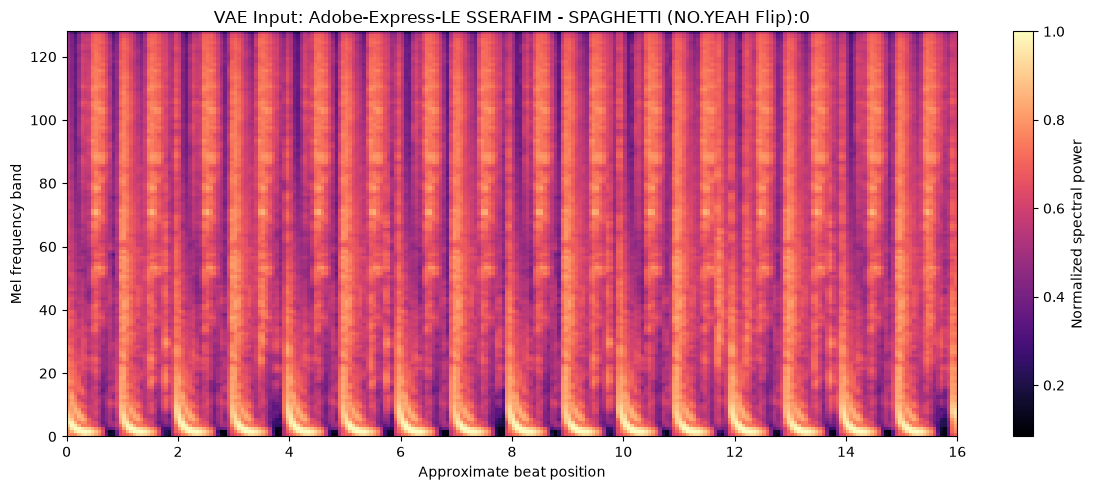

In [29]:
#VISUALIZATION of what the VAE will see
plt.figure(figsize=(12, 5))

plt.imshow(
    test_spectrogram,
    origin="lower",
    aspect="auto",
    cmap="magma",
    extent=[0, 16, 0, N_MELS]
)

plt.colorbar(label="Normalized spectral power")

plt.xlabel("Approximate beat position")
plt.ylabel("Mel frequency band")

plt.title(
    f"VAE Input: {test_segment.segment_id}"
)

plt.tight_layout()
plt.show()

this highlights the first four bars of one of our song segments. The horizontal axis represents musical progression, the vertical axis represents frequency bands, and brighter regions represent stronger spectral content.
- Frequency bands: specific slices or ranges of frequencies along the vertical axis that group audio energy by pitch (like bass, mids, etc)

## VAE training dataset

In [35]:
spectrograms = []
vae_segment_ids = []
vae_song_ids = []
failed_segments = []

for i, segment in enumerate(segments):

    try:
        spec = segment_to_spectrogram(segment)

        if spec.shape != (N_MELS, TARGET_FRAMES):
            raise ValueError("Incorrect spectrogram shape")

        if not np.isfinite(spec).all():
            raise ValueError("Non-finite spectrogram values")

        spectrograms.append(spec)
        vae_segment_ids.append(segment.segment_id)
        vae_song_ids.append(segment.song_id)

    except Exception as e:
        failed_segments.append(
            (segment.segment_id, str(e))
        )

    # if (i + 1) % 10 == 0 or i + 1 == len(segments):
    #     print(f"Processed {i + 1}/{len(segments)} segments")

if not spectrograms:
    raise ValueError("No valid spectrograms generated")

spectrograms = np.stack(spectrograms)

print("\nDATASET COMPLETE")
# print("----------------------------")
# print("Dataset shape:", spectrograms.shape)
# print("Successful segments:", len(vae_segment_ids))
# print("Failed segments:", len(failed_segments))
# print("Unique songs:", len(set(vae_song_ids)))
# print("Data type:", spectrograms.dtype)
# print("Memory usage (MB):", spectrograms.nbytes / 1e6)


DATASET COMPLETE


In [38]:
# print("DATASET STATISTICS")
# print("----------------------------")

# print("Minimum:", spectrograms.min())
# print("Maximum:", spectrograms.max())
# print("Mean:", spectrograms.mean())
# print("Standard deviation:", spectrograms.std())

# print("\nNORMALIZATION CHECK")
# print("----------------------------")

# print(
#     "Percentage at lower limit:",
#     100 * np.mean(spectrograms <= 0.0)
# )

# print(
#     "Percentage at upper limit:",
#     100 * np.mean(spectrograms >= 1.0)
# )

# print(
#     "Contains NaN:",
#     np.isnan(spectrograms).any()
# )

# print(
#     "Contains infinity:",
#     np.isinf(spectrograms).any()
# )

# print("\nSEGMENTS PER SONG")
# print("----------------------------")

# from collections import Counter

# for song, count in Counter(vae_song_ids).items():
#     print(f"{song}: {count}")

In [32]:
## We convert the spectrograms to a PyTorch tensor for VAE input
# Our spectograms have one channel because each time-frequency position
# contains a single spectral intensity value
vae_tensor = torch.from_numpy(
    spectrograms
).unsqueeze(1)

print("Original NumPy shape:", spectrograms.shape)
print("PyTorch tensor shape:", vae_tensor.shape)
print("Tensor data type:", vae_tensor.dtype)

Original NumPy shape: (149, 128, 256)
PyTorch tensor shape: torch.Size([149, 1, 128, 256])
Tensor data type: torch.float32


In [ ]:
#saving the generated spectograms locally so that we don't
#recalculate every spectogram each time we run the notebook
# This will save the dataset to a compressed .npz file in the processed directory.

from pathlib import Path

cache_dir = AUDIO_DIR.parent / "processed"
cache_dir.mkdir(parents=True, exist_ok=True)

dataset_path = cache_dir / "vae_dataset.npz"

np.savez_compressed(
    dataset_path,
    spectrograms=spectrograms,
    segment_ids=np.array(vae_segment_ids),
    song_ids=np.array(vae_song_ids),
    sample_rate=VAE_SR,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    target_frames=TARGET_FRAMES
)

print("Dataset saved to:")
print(dataset_path.resolve())

Dataset saved to:
C:\Users\Owner\Downloads\DJAIvscode\data\processed\vae_dataset.npz


## Constructing the vae

A variational autoencoder instead learns a probability distribution for each input.

           TRADITIONAL AUTOENCODER

Input ──► Encoder ──► z ──► Decoder ──► Output



      VARIATIONAL AUTOENCODER

                 μ
               ╱   ╲

Inp. ──► Enco. ____ Sampl. ──► z ──► Deco. ──► Out.

               ╲   ╱
               log σ²

For DJAI, our input is a spectrogram representing four bars of music.

Our objective is to learn a compact, continuous latent space that represents the characteristics of those musical segments.

because spectograms have both frequency and time dimensions, we're going to use a conv. vae. Convolutional layers can learn local patterns, including recurring rhythmic structures, frequency relationship, and spectral textures.

## VAE architecture and data splitting

In [39]:
from torch.utils.data import TensorDataset, DataLoader

# Hold out one complete song for validation
validation_song = sorted(set(vae_song_ids))[-1]

song_array = np.array(vae_song_ids)

train_mask = song_array != validation_song
val_mask = song_array == validation_song

X_train = vae_tensor[train_mask]
X_val = vae_tensor[val_mask]

train_dataset = TensorDataset(X_train)
val_dataset = TensorDataset(X_val)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Validation song:", validation_song)
print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Validation song: Yeah Yeah Yeahs - Heads Will Roll (ZUEZEU Remix) [Extended Mix]
Training shape: torch.Size([134, 1, 128, 256])
Validation shape: torch.Size([15, 1, 128, 256])
Training batches: 9
Validation batches: 1


In [40]:
class Encoder(nn.Module): #we're using an off the shelf model

    def __init__(self, latent_dim=16):
        super().__init__()

        # the encoder takes our o.g spectogram and progressively reduces its spatial dimensions through a series of convolutional layers

        self.conv = nn.Sequential( #sequence of layers

            nn.Conv2d(  #  1x128x256 -> 8x64x128
                1, 8,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(), #non-linear activation function

            nn.Conv2d( #  8x64x128 -> 16x32x64
                8, 16,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(), #non-linear activation function

            nn.Conv2d( #  16x32x64 -> 32x16x32
                16, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(), #non-linear activation function

            nn.Conv2d( #  32x16x32 -> 32x8x16
                32, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU() #non-linear activation function
        )

        self.flatten = nn.Flatten()  # flatten the output of the convolutional layers for the fully connected layers

        self.fc_mu = nn.Linear( #  4096 -> latent_dim
            4096, latent_dim
        )

        self.fc_logvar = nn.Linear( #  4096 -> latent_dim   
            4096, latent_dim
        )

    def forward(self, x):

        x = self.conv(x)
        x = self.flatten(x)

        mu = self.fc_mu(x) #mu is the mean of the latent probability distribution
        logvar = self.fc_logvar(x) #logvar is a representation of the uncertainty or spread of that distribution

        return mu, logvar

In [45]:
#directly sampling from a distribution parameterized by the encoder
# makes ordingary backprop. impossible, so we add randomness (epsilon),
# so that we can train the encoder.
def reparameterize(mu, logvar):

    std = torch.exp(0.5 * logvar) #ensures st dev remains positive

    epsilon = torch.randn_like(std) #this is the randomness

    z = mu + std * epsilon

    return z

In [41]:
#this is literally the exact same as the encoder but in the opposite direction
class Decoder(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.fc = nn.Linear(
            latent_dim, 4096
        )

        self.deconv = nn.Sequential(

            nn.ConvTranspose2d( #instead of conv2d, we use transpose. this is because
                # transpose2d doubles the spatial dimensions instead of reducing them
                # 32x8x16 -> 32x16x32
                32, 32,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d( #  32x16x32 -> 16x32x64
                32, 16,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d( #  16x32x64 -> 8x64x128
                16, 8,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(),

            nn.ConvTranspose2d( #  8x64x128 -> 1x128x256
                8, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Sigmoid() #we use sigmoid here to ensure the output is between 0 and 1 (like the input spectrogram)
        )

    def forward(self, z):

        x = self.fc(z)

        x = x.reshape(-1, 32, 8, 16)

        x = self.deconv(x)

        return x

## putting together the model

In [42]:
class DJAI_VAE(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):

        mu, logvar = self.encoder(x)

        z = reparameterize(mu, logvar)

        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar

In [43]:
#instantiate the model
model = DJAI_VAE(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(model)

total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("\nTotal parameters:", total_parameters)
print("Device:", DEVICE)

DJAI_VAE(
  (encoder): Encoder(
    (conv): Sequential(
      (0): Conv2d(1, 8, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(8, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (5): ReLU()
      (6): Conv2d(32, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (7): ReLU()
    )
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc_mu): Linear(in_features=4096, out_features=16, bias=True)
    (fc_logvar): Linear(in_features=4096, out_features=16, bias=True)
  )
  (decoder): Decoder(
    (fc): Linear(in_features=16, out_features=4096, bias=True)
    (deconv): Sequential(
      (0): ConvTranspose2d(32, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU()
      (2): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU()
      (4): ConvTranspose2d(16, 8, kernel_size=(4, 4), 

In [47]:
# test the complete forward pass
model.eval()

test_batch = next(iter(train_loader))[0]
test_batch = test_batch.to(DEVICE)

with torch.no_grad():

    reconstruction, mu, logvar = model(test_batch)

print("FORWARD PASS TEST")
print("----------------------------")

print("Input shape:", test_batch.shape)
print("Mean shape:", mu.shape)
print("Log variance shape:", logvar.shape)
print("Reconstruction shape:", reconstruction.shape)

print(
    "Reconstruction minimum:",
    reconstruction.min().item()
)

print(
    "Reconstruction maximum:",
    reconstruction.max().item()
)

assert reconstruction.shape == test_batch.shape

print("\nForward pass successful!")

FORWARD PASS TEST
----------------------------
Input shape: torch.Size([16, 1, 128, 256])
Mean shape: torch.Size([16, 16])
Log variance shape: torch.Size([16, 16])
Reconstruction shape: torch.Size([16, 1, 128, 256])
Reconstruction minimum: 0.46239742636680603
Reconstruction maximum: 0.507796585559845

Forward pass successful!


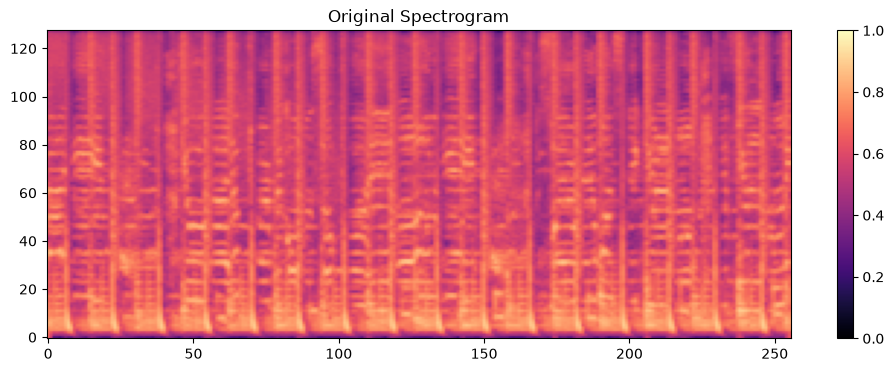

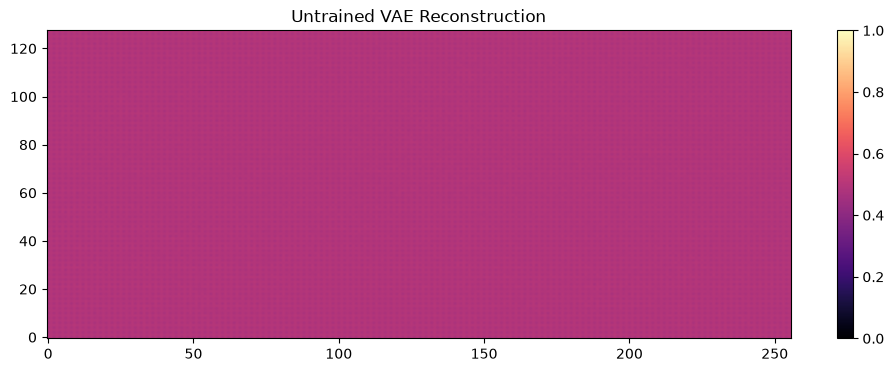

In [48]:
#visualize results
original = test_batch[0, 0].cpu().numpy()

reconstructed = (
    reconstruction[0, 0].cpu().numpy()
)

plt.figure(figsize=(12, 4))

plt.imshow(
    original,
    origin="lower",
    aspect="auto",
    cmap="magma",
    vmin=0,
    vmax=1
)

plt.title("Original Spectrogram")
plt.colorbar()
plt.show()

plt.figure(figsize=(12, 4))

plt.imshow(
    reconstructed,
    origin="lower",
    aspect="auto",
    cmap="magma",
    vmin=0,
    vmax=1
)

plt.title("Untrained VAE Reconstruction")
plt.colorbar()
plt.show()

## introduction of loss (which we can see that we need from above)

The vae loss function has two competing training objectives. Reconstruction loss that aims to have the reconstructed spectogram resemble the original spectogram (using mean squared error)...

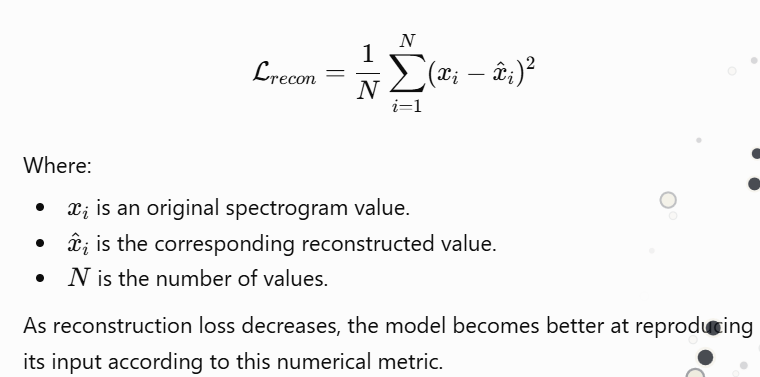

...and KL divergence which measures how different our learned latent distribution is from a standard normal distribution.

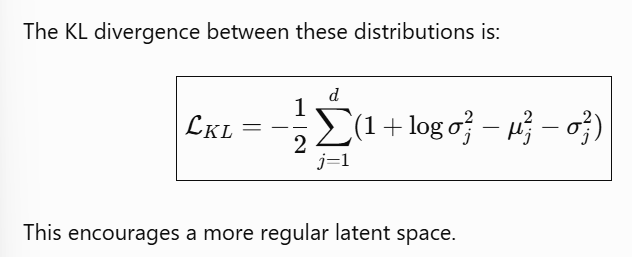

**important to know: we also use a beta parameter that controls how strongly we enforce latent-space regularization.
- we need to watch out for posterior collapse where the decoder learns to reconstruct generic spectrograms while largely ignoring the latent vector.

- For DJAI, that would be particularly problematic because the latent representation is the part we ultimately want to use.

- We'll initially use a technique called KL annealing, gradually increasing beta during training.

In [49]:
# loss function
def vae_loss(reconstruction, original, mu, logvar, beta):

    # Reconstruction loss
    recon_loss = F.mse_loss(
        reconstruction,
        original,
        reduction="mean"
    )

    # KL divergence, averaged across the batch
    kl_loss = -0.5 * torch.mean(
        torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp(),
            dim=1
        )
    )

    # Combined VAE objective
    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

#we're returning all 3 losses separately to track them during training

In [50]:
import time

EPOCHS = 30
LEARNING_RATE = 0.001

BETA_MAX = 0.0001
WARMUP_EPOCHS = 10

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    "train_total": [],
    "train_recon": [],
    "train_kl": [],
    "val_total": [],
    "val_recon": [],
    "val_kl": [],
    "beta": []
}

print("Training configuration ready.")

Training configuration ready.


In [51]:
#OUR MODEL ACTUALLY STARTS LEARNING NOW

start_time = time.time()

for epoch in range(EPOCHS):

    # Gradually increase KL regularization
    beta = BETA_MAX * min(
        1.0,
        (epoch + 1) / WARMUP_EPOCHS
    )

    # ----------------------------------------
    # TRAINING
    # ----------------------------------------

    model.train()

    train_total = 0.0
    train_recon = 0.0
    train_kl = 0.0

    for (x,) in train_loader:

        x = x.to(DEVICE)

        optimizer.zero_grad()

        reconstruction, mu, logvar = model(x)

        loss, recon_loss, kl_loss = vae_loss(
            reconstruction,
            x,
            mu,
            logvar,
            beta
        )

        loss.backward()

        optimizer.step()

        batch_size = x.size(0)

        train_total += loss.item() * batch_size
        train_recon += recon_loss.item() * batch_size
        train_kl += kl_loss.item() * batch_size

    train_total /= len(train_dataset)
    train_recon /= len(train_dataset)
    train_kl /= len(train_dataset)

    # ----------------------------------------
    # VALIDATION
    # ----------------------------------------

    model.eval()

    val_total = 0.0
    val_recon = 0.0
    val_kl = 0.0

    with torch.no_grad():

        for (x,) in val_loader:

            x = x.to(DEVICE)

            reconstruction, mu, logvar = model(x)

            loss, recon_loss, kl_loss = vae_loss(
                reconstruction,
                x,
                mu,
                logvar,
                beta
            )

            batch_size = x.size(0)

            val_total += loss.item() * batch_size
            val_recon += recon_loss.item() * batch_size
            val_kl += kl_loss.item() * batch_size

    val_total /= len(val_dataset)
    val_recon /= len(val_dataset)
    val_kl /= len(val_dataset)

    # ----------------------------------------
    # RECORD RESULTS
    # ----------------------------------------

    history["train_total"].append(train_total)
    history["train_recon"].append(train_recon)
    history["train_kl"].append(train_kl)

    history["val_total"].append(val_total)
    history["val_recon"].append(val_recon)
    history["val_kl"].append(val_kl)

    history["beta"].append(beta)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train MSE: {train_recon:.6f} | "
        f"Val MSE: {val_recon:.6f} | "
        f"KL: {train_kl:.4f} | "
        f"Beta: {beta:.6f}",
        flush=True
    )

elapsed = time.time() - start_time

print("\nTRAINING COMPLETE")
print(f"Training time: {elapsed / 60:.2f} minutes")

Epoch 01/30 | Train MSE: 0.032409 | Val MSE: 0.020815 | KL: 88.5804 | Beta: 0.000010
Epoch 02/30 | Train MSE: 0.019894 | Val MSE: 0.015268 | KL: 83.0031 | Beta: 0.000020
Epoch 03/30 | Train MSE: 0.013880 | Val MSE: 0.014058 | KL: 17.4040 | Beta: 0.000030
Epoch 04/30 | Train MSE: 0.011663 | Val MSE: 0.012362 | KL: 10.2873 | Beta: 0.000040
Epoch 05/30 | Train MSE: 0.010652 | Val MSE: 0.012208 | KL: 9.3946 | Beta: 0.000050
Epoch 06/30 | Train MSE: 0.010542 | Val MSE: 0.010719 | KL: 8.6635 | Beta: 0.000060
Epoch 07/30 | Train MSE: 0.009803 | Val MSE: 0.010432 | KL: 12.3853 | Beta: 0.000070
Epoch 08/30 | Train MSE: 0.009667 | Val MSE: 0.010564 | KL: 12.3354 | Beta: 0.000080
Epoch 09/30 | Train MSE: 0.009727 | Val MSE: 0.010574 | KL: 9.6690 | Beta: 0.000090
Epoch 10/30 | Train MSE: 0.009193 | Val MSE: 0.010140 | KL: 7.8300 | Beta: 0.000100
Epoch 11/30 | Train MSE: 0.008916 | Val MSE: 0.010068 | KL: 7.9484 | Beta: 0.000100
Epoch 12/30 | Train MSE: 0.008552 | Val MSE: 0.009858 | KL: 7.9448 | B

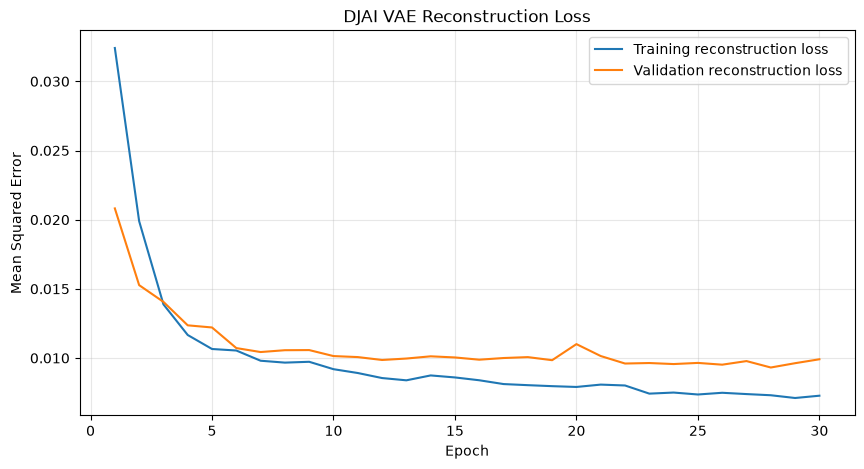

In [52]:
#visualize the training performance
epochs = range(1, len(history["train_recon"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_recon"],
    label="Training reconstruction loss"
)

plt.plot(
    epochs,
    history["val_recon"],
    label="Validation reconstruction loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("DJAI VAE Reconstruction Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

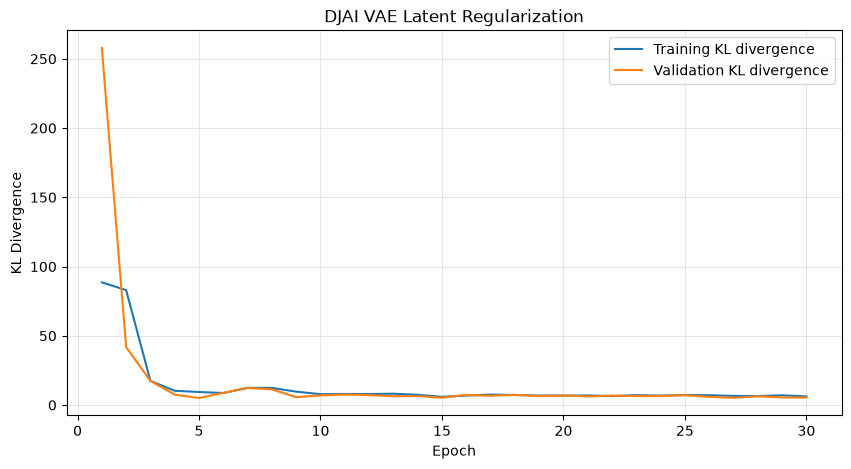

In [53]:
#plotting kl divergence
plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_kl"],
    label="Training KL divergence"
)

plt.plot(
    epochs,
    history["val_kl"],
    label="Validation KL divergence"
)

plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.title("DJAI VAE Latent Regularization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## repeating our first attempt at reconstruction

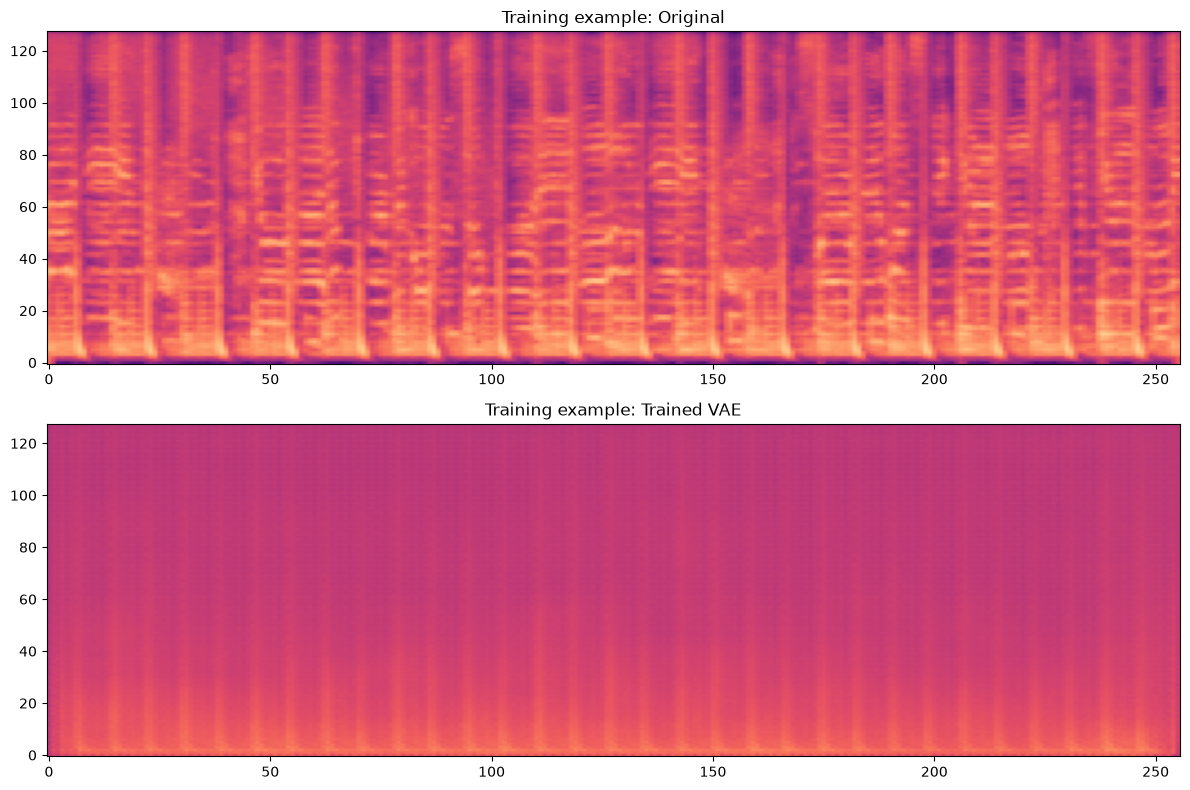

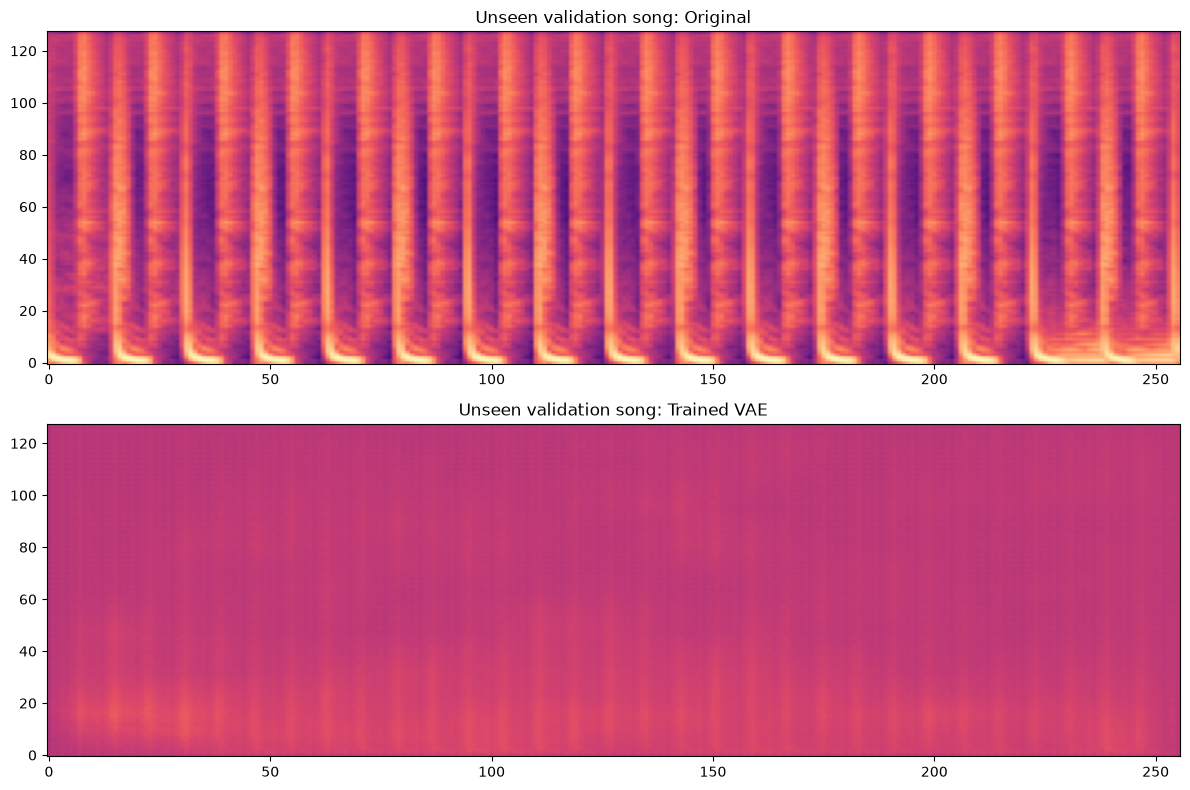

In [54]:
model.eval()

examples = {
    "Training example": test_batch[:1],
    "Unseen validation song": X_val[:1]
}

for label, example in examples.items():

    example = example.to(DEVICE)

    with torch.no_grad():

        mu, logvar = model.encoder(example)

        # Use the distribution mean for
        # reproducible reconstruction
        reconstructed = model.decoder(mu)

    original_spec = example[0, 0].cpu().numpy()

    reconstructed_spec = (
        reconstructed[0, 0].cpu().numpy()
    )

    fig, axes = plt.subplots(
        2, 1,
        figsize=(12, 8)
    )

    axes[0].imshow(
        original_spec,
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=0,
        vmax=1
    )

    axes[0].set_title(f"{label}: Original")

    axes[1].imshow(
        reconstructed_spec,
        origin="lower",
        aspect="auto",
        cmap="magma",
        vmin=0,
        vmax=1
    )

    axes[1].set_title(f"{label}: Trained VAE")

    plt.tight_layout()
    plt.show()

In [55]:
#save the trained model
model_dir = AUDIO_DIR.parent.parent / "models"

model_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_path = model_dir / "djai_vae_v1.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "latent_dim": LATENT_DIM,
        "n_mels": N_MELS,
        "target_frames": TARGET_FRAMES,
        "sample_rate": VAE_SR,
        "n_fft": N_FFT,
        "hop_length": HOP_LENGTH,
        "beta_max": BETA_MAX,
        "validation_song": validation_song,
        "history": history
    },
    model_path
)

print("Model saved to:")
print(model_path.resolve())

Model saved to:
C:\Users\Owner\Downloads\DJAIvscode\models\djai_vae_v1.pt
